In [1]:
from lights.plotting import setup_style
from lights.constants import mB, mK
from lights.form_factors import a_vals_gen
from lights.branching_fractions import dBdqsq_SM
from lights.models import Model, K

import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

setup_style()

In [2]:
psipsi = Model("psipsi", 0.6, Lambda = 1e4, CVL = 1., CVR = 1.)

BR_SM = quad(lambda qsq: dBdqsq_SM(qsq)[K], 1e-12, (mB - mK)**2)[0]
BR_psipsi = quad(lambda qsq: psipsi.dBdqsq(qsq)[K], 4*psipsi.mX**2, (mB - mK)**2)[0]
BR_SM, BR_psipsi

(4.904149612207374e-06, 9.596606009134639e-06)

In [3]:
# Form factor toys (reproducible: fixed seed)
a_vals_r = a_vals_gen(10000, rng = 1)

qsq_vals = np.linspace(0.0001, (mB - mK)**2, 200)

def band(rate, norm):
    "Mean and standard deviation over the form factor toys of rate(a_vals), divided by norm."
    vals = np.array([rate(a_vals) for a_vals in a_vals_r]) / norm
    return vals.mean(axis = 0), vals.std(axis = 0)

band_SM = band(lambda a_vals: dBdqsq_SM(qsq_vals, a_vals = a_vals)[K], BR_SM)
band_psipsi = band(lambda a_vals: psipsi.dBdqsq(qsq_vals, a_vals)[K], BR_psipsi)

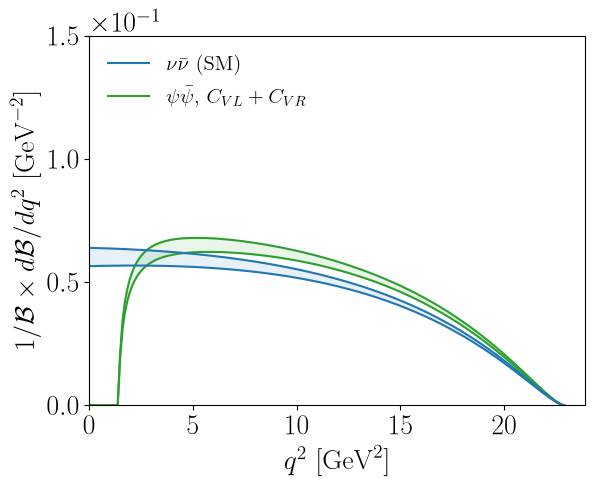

In [4]:
def plot_band(axes, band, color):
    "Mean +- standard deviation band, returns the line for the legend."
    mean, std = band
    line, = axes.plot(qsq_vals, mean + std, color = color)
    axes.plot(qsq_vals, mean - std, color = color)
    axes.fill_between(qsq_vals, mean - std, mean + std, color = color, alpha = 0.1)
    return line

fig, axes = plt.subplots(nrows=1, ncols=1)

tot3 = plot_band(axes, band_psipsi, 'C2')
tot1 = plot_band(axes, band_SM, 'C0')

axes.set_yticks([0, 0.05, 0.1, 0.15])

axes.set_xlim(0, (mB - mK)**2+1)
axes.set_ylim(0,0.15)

axes.set_xlabel(r'$q^2 ~[\mathrm{GeV}^2]$');
axes.set_ylabel(r'$1/\mathcal{B} \times d\mathcal{B}/dq^2 ~[\mathrm{GeV}^{-2}]$')

axes.legend([tot1,tot3], [r'$\nu\bar{\nu}$ (SM)',r'$\psi \bar{\psi}$, $C_{VL} + C_{VR}$'], loc='upper left',fontsize=15,frameon=False)

plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

fig.set_size_inches(6.4, 4.8)